In [1]:
import warnings
warnings.filterwarnings('ignore')

# Example: explanability for forecasting: exponential decay in the past window in the close up for PAST-LOAD.

In [2]:
# Basic libraries
import numpy as np
import pandas as pd
import pickle as pk
import random
import time_explainer as time
import matplotlib.pyplot as plt
import plotly.graph_objects as go 
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px
from tensorflow.keras.models import load_model

In [3]:
import sys
import tensorflow as tf
import keras

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

Python: /Users/juliowaissman/Documents/explaniability-forecasting-with-close-up/venv/bin/python
TensorFlow: 2.15.1
Keras: 2.15.0


If Keras is 3.X, execute the next cell and restart the kernel. If Keras is 2.X, skip the next cell and continue with the notebook.

In [ ]:
import sys
!{sys.executable} -m pip uninstall -y tensorflow keras
!{sys.executable} -m pip install tensorflow==2.15.1 keras==2.15.0

### Model ALL: LSTM encoder-decoder, the decoder receives calendar, weather, and holiday information in advance

#### Training model $f_\theta$

In [4]:
# Download the model
path = 'data/calendar_weather_holiday_in_advance/'  
model_name = 'model_calendar_wather_holiday_in_advance.h5'
model = load_model(path + model_name)
model.summary()

Model: "ALL"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 encoder_inputs (InputLayer  [(None, 180, 15)]            0         []                            
 )                                                                                                
                                                                                                  
 decoder_inputs (InputLayer  [(None, 36, 14)]             0         []                            
 )                                                                                                
                                                                                                  
 lstm (LSTM)                 [(None, 100),                46400     ['encoder_inputs[0][0]']      
                              (None, 100),                                                      

In [5]:
## Get sample (100 random samples) of the training set to use in the notebook
with open(path + 'X_train_sample.pkl', 'rb') as f:
    X_train_sample = pk.load(f)

#### Initial interpretable decomposition of  $X$ in the domain of $f_\theta$

In [6]:
with open(path + 'X_encoder_test.pkl', 'rb') as f:
    X_encoder_test = pk.load(f)

with open(path + 'X_decoder_test.pkl', 'rb') as f:
    X_decoder_test = pk.load(f)

X_observation = [X_encoder_test[0], X_decoder_test[0]]

# ITERATION 1

In [7]:
### Initial decomposition configuration
component_names = ['past-load','calendar','weather','holiday']

def FTP_initial(X):
    X_split = {0: X[0][:,0:1], # past-load
               1: [X[0][:,1:4],X[1][:,0:3]], # calendar
               2: [X[0][:,4:5],X[1][:,3:4]], # weather
               3: [X[0][:,5:15],X[1][:,4:14]]# holiday
                }         
    return X_split

def joint_FTP_initial(X_split):
    X_encoder = np.concatenate([X_split[0],X_split[1][0],X_split[2][0],X_split[3][0]], axis = 1).reshape(180, 15)
    X_decoder = np.concatenate([X_split[1][1],X_split[2][1],X_split[3][1]], axis = 1).reshape(36, 14)
    return [X_encoder,X_decoder]

In [8]:
FTP_initial = time.elements(model, 
                            X_train_sample, 
                            split_func=FTP_initial, 
                            joint_func=joint_FTP_initial
                           )

In [9]:
initial_explainability_model = FTP_initial.explainability_model(X_observation)
fig = time.local_plot(initial_explainability_model,component_names)
fig.show()

4/4 [==============================] - 0s 10ms/step


In [10]:
phi_zero = initial_explainability_model[0]
phi_uno = model.predict([X_encoder_test[0].reshape(1,180,15), X_decoder_test[0].reshape(1,36,14)]).reshape(36,)
N = np.array([1/x for x in phi_uno - phi_zero]) # normalization constants
print(N.shape)

1/1 [==============================] - 0s 13ms/step
(36,)


In [11]:
def rgb_to_rgba(rgb_value, alpha):
    """
    Adds the alpha channel to an RGB Value and returns it as an RGBA Value
    :param rgb_value: Input RGB Value
    :param alpha: Alpha Value to add  in range [0,1]
    :return: RGBA Value
    """
    return f"rgba{rgb_value[3:-1]}, {alpha})"

In [12]:
m = 1
fig = go.Figure()
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(size=11,color='gray'),
    font_family='Helvetica'
)
x = list(range(0,36,m))
y = [initial_explainability_model[1][0][t] for t in range(0,36,m)]
fig.add_trace(go.Bar(x=x, y=y, showlegend = False,
                    marker=dict(color=[rgb_to_rgba(px.colors.qualitative.Prism[int((t-1)/4)],1) for t in x], # Data used for color mapping
                                showscale=False),
                       text=[str(t+1) for t in x],
                       textposition='auto'

                    ))
fig.update_yaxes(showticklabels=True)
fig.update_xaxes(showticklabels=False)
fig.update_yaxes(title_text='past load demand explanations')
fig.update_xaxes(title_text='future window (forecasted hours)')
fig.update_traces(showlegend=False)
fig.show()
#fig.write_image('past_load.pdf') 

In [13]:
m=1
fig = go.Figure()
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(size=11,color='gray'),
    font_family='Helvetica',
    width=1000
)
x = list(range(-180, 1, 1))
for t in range(0,36,m):
    color_index =  int((t-1)/4)
    past_load_explain_encoder = np.concatenate([np.ones(180) * initial_explainability_model[1][0][t]/180])
    fig.add_trace(go.Line(x=x, y=past_load_explain_encoder,
                    fill='tozeroy',
                    line=dict(color=rgb_to_rgba(px.colors.qualitative.Prism[color_index],1)),
                    name='h: ' + str(t+1)))
    fig.update_xaxes(title_text='past window hours (encoder)')
    fig.update_yaxes(showticklabels=False)
    fig.update_traces(showlegend=False)
fig.show()
#fig.write_image('past_load_initial.pdf') 

/Users/juliowaissman/Documents/explaniability-forecasting-with-close-up/venv/lib/python3.9/site-packages/plotly/graph_objs/_deprecations.py:378: DeprecationWarning: plotly.graph_objs.Line is deprecated.
Please replace it with one of the following more specific types
  - plotly.graph_objs.scatter.Line
  - plotly.graph_objs.layout.shape.Line
  - etc.

  warnings.warn(


# Iteration 1

In [14]:
## Zoom over past-load
component_names = ['[-180,-120)','[-120,-60)','[-60,0]']

def past_load_zoom_1(X):
    X_split = {0: X[0][:-120,0:1], # '[-180,-120)'
               1: X[0][-120:-60,0:1], # [-120,-60)
               2: X[0][-60:,0:1], # [-60,0]
               'rest_calendar':[X[0][:,1:4],X[1][:,0:3]], # fixed rest
               'rest_weather': [X[0][:,4:5],X[1][:,3:4]], # fixed rest
               'rest_holiday': [X[0][:,5:15],X[1][:,4:14]] # fixed rest 
                }         
    return X_split

def join_past_load_zoom_1(X_split):
    X_past_load = np.concatenate([X_split[0],X_split[1],X_split[2]], axis = 0).reshape(180, 1)
    X_encoder = np.concatenate([X_past_load,X_split['rest_calendar'][0], X_split['rest_weather'][0], X_split['rest_holiday'][0]], axis = 1).reshape(180, 15)
    X_decoder = np.concatenate([X_split['rest_calendar'][1],X_split['rest_weather'][1],X_split['rest_holiday'][1]], axis = 1).reshape(36, 14)
    return [X_encoder,X_decoder]

In [15]:
phi_zero = initial_explainability_model[0]
phi_close_up = initial_explainability_model[1][0]
past_load_zoom_1 = time.elements(model,
                                 X_train_sample, 
                                 component_to_close_up=phi_close_up, 
                                 initial_bias=phi_zero, 
                                 split_func=past_load_zoom_1, 
                                 joint_func=join_past_load_zoom_1
                                )

In [16]:
past_load_zoom_1_model = past_load_zoom_1.close_up_explainability_model(X_observation)
base_vector = -phi_zero
fig = time.local_plot(past_load_zoom_1_model,component_names,base_vector)
fig.show()

4/4 [==============================] - 0s 12ms/step


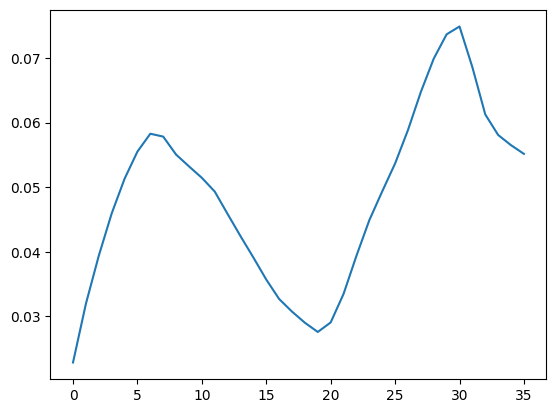

In [17]:
e = past_load_zoom_1_model[2]
plt.plot(e)  
plt.show()

In [18]:
e.mean()

0.04852680262914037

In [19]:
np.linalg.norm(e, ord=np.inf)

0.07488972362544799

<function matplotlib.pyplot.show(close=None, block=None)>

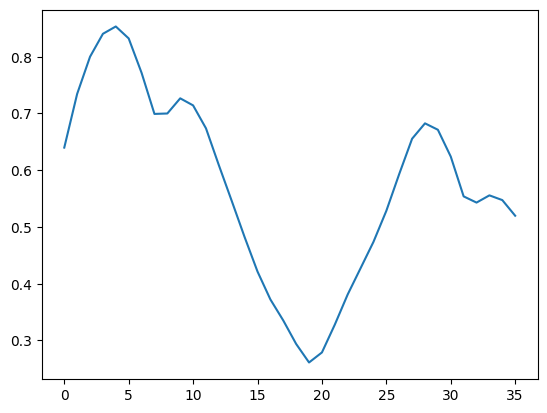

In [20]:
contribution = np.array([phi_close_up[i]/N[i] for i in range(36)])
plt.plot(contribution)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

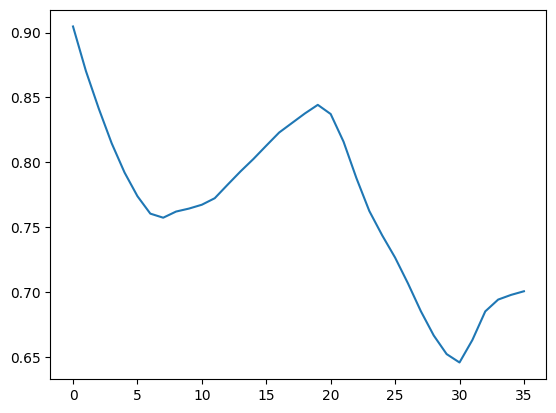

In [21]:
alpha = np.array([e[i]/phi_close_up[i] for i in range(36)])
n = 3
proportion = 1-3*alpha
plt.plot(proportion)
plt.show

In [22]:
m=1
fig = go.Figure()
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(size=11,color='gray'),
    font_family='Helvetica',
    width=1000
)
x = list(range(-180, 1, 1))
for t in range(0,36,m):
    color_index =  int((t-1)/4)
    load_explain = np.concatenate([np.ones(60) * past_load_zoom_1_model[1][0][t]/60, 
                              np.ones(60) * past_load_zoom_1_model[1][1][t]/60,
                              np.ones(60) * past_load_zoom_1_model[1][2][t]/60]
                                 )
    fig.add_trace(go.Line(x=x, y=load_explain,
                    fill='tozeroy',
                    line=dict(color=rgb_to_rgba(px.colors.qualitative.Prism[color_index],1)),
                    name='h: ' + str(t+1)))
    fig.update_yaxes(showticklabels=False)
    fig.update_xaxes(title_text='past window hours')
    fig.update_traces(showlegend=False)
fig.show()

/Users/juliowaissman/Documents/explaniability-forecasting-with-close-up/venv/lib/python3.9/site-packages/plotly/graph_objs/_deprecations.py:378: DeprecationWarning: plotly.graph_objs.Line is deprecated.
Please replace it with one of the following more specific types
  - plotly.graph_objs.scatter.Line
  - plotly.graph_objs.layout.shape.Line
  - etc.

  warnings.warn(


# Iteration 2

In [23]:
## Zoom over [-120,-60)
component_names = ['[-120,-100)','[-100,-80)','[-80,-60)']

def past_load_zoom_2(X):
    X_split = {'rest_load_before': X[0][:-120,0:1], # fixed rest
               0: X[0][-120:-100,0:1], # [-120,-100)
               1: X[0][-100:-80,0:1], # [-100,-80)
               2: X[0][-80:-60,0:1], # [-80,-60)
               'rest_load_after': X[0][-60:,0:1], # fixed rest
               'rest_calendar':[X[0][:,1:4],X[1][:,0:3]], # fixed rest
               'rest_weather': [X[0][:,4:5],X[1][:,3:4]], # fixed rest
               'rest_holiday': [X[0][:,5:15],X[1][:,4:14]] # fixed rest 
                }         
    return X_split

def join_past_load_zoom_2(X_split):
    X_past_load = np.concatenate([X_split['rest_load_before'],X_split[0],X_split[1],X_split[2],X_split['rest_load_after']], axis = 0).reshape(180, 1)
    X_encoder = np.concatenate([X_past_load,X_split['rest_calendar'][0], X_split['rest_weather'][0], X_split['rest_holiday'][0]], axis = 1).reshape(180, 15)
    X_decoder = np.concatenate([X_split['rest_calendar'][1],X_split['rest_weather'][1],X_split['rest_holiday'][1]], axis = 1).reshape(36, 14)
    return [X_encoder,X_decoder]

In [24]:
phi_zero = initial_explainability_model[0]
phi_close_up = past_load_zoom_1_model[1][1]
past_load_zoom_2 = time.elements(model, 
                                 X_train_sample, 
                                 component_to_close_up=phi_close_up, 
                                 initial_bias=phi_zero, 
                                 split_func=past_load_zoom_2, 
                                 joint_func=join_past_load_zoom_2
                                )

In [25]:
past_load_zoom_2_model = past_load_zoom_2.close_up_explainability_model(X_observation)
base_vector = -phi_zero
fig = time.local_plot(past_load_zoom_2_model,component_names,base_vector)
fig.show()

4/4 [==============================] - 0s 10ms/step


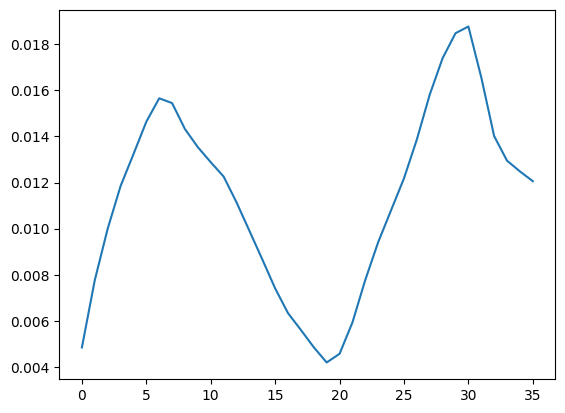

In [26]:
e = past_load_zoom_2_model[2]
plt.plot(e)  
plt.show()

In [27]:
e.mean()

0.011322338540306266

In [28]:
np.linalg.norm(e, ord=np.inf)

0.018765045674862632

<function matplotlib.pyplot.show(close=None, block=None)>

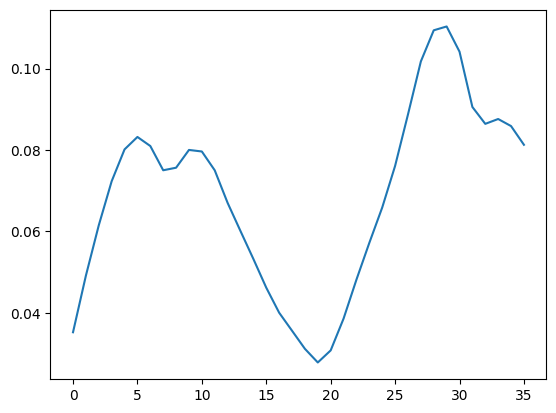

In [29]:
contribution = np.array([phi_close_up[i]/N[i] for i in range(36)])
plt.plot(contribution)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

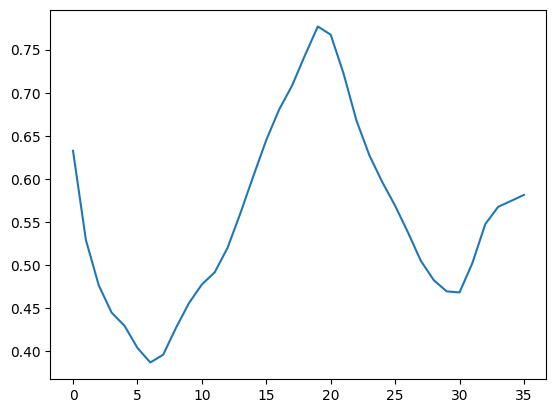

In [30]:
alpha = np.array([e[i]/phi_close_up[i] for i in range(36)])
n = 3
proportion = 1-n*alpha
plt.plot(proportion)
plt.show

In [31]:
m=1
fig = go.Figure()
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(size=11,color='gray'),
    font_family='Helvetica',
    width=1000
)
x = list(range(-180, 1, 1))
for t in range(0,36,m):
    color_index =  int((t-1)/4)
    load_explain = np.concatenate([np.ones(60) * past_load_zoom_1_model[1][0][t]/60, 
                              np.ones(20) * past_load_zoom_2_model[1][0][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][1][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][2][t]/20,     
                              np.ones(60) * past_load_zoom_1_model[1][2][t]/60]
                                 )
    fig.add_trace(go.Line(x=x, y=load_explain,
                    fill='tozeroy',
                    line=dict(color=rgb_to_rgba(px.colors.qualitative.Prism[color_index],1)),
                    name='h: ' + str(t+1)))
    fig.update_yaxes(showticklabels=False)
    fig.update_xaxes(title_text='past window hours')
    fig.update_traces(showlegend=False)
fig.show()

/Users/juliowaissman/Documents/explaniability-forecasting-with-close-up/venv/lib/python3.9/site-packages/plotly/graph_objs/_deprecations.py:378: DeprecationWarning: plotly.graph_objs.Line is deprecated.
Please replace it with one of the following more specific types
  - plotly.graph_objs.scatter.Line
  - plotly.graph_objs.layout.shape.Line
  - etc.

  warnings.warn(


In [32]:
## Zoom over [-60,0]
component_names = ['[-60,-40)','[-40,-20)','[-20,0]']

def past_load_zoom_3(X):
    X_split = {'rest_load_before': X[0][:-60,0:1], # fixed rest
               0: X[0][-60:-40,0:1], # [-60,-40)
               1: X[0][-40:-20,0:1], # [-40,-20)
               2: X[0][-20:,0:1], # [-20,0]
               'rest_calendar':[X[0][:,1:4],X[1][:,0:3]], # fixed rest
               'rest_weather': [X[0][:,4:5],X[1][:,3:4]], # fixed rest
               'rest_holiday': [X[0][:,5:15],X[1][:,4:14]] # fixed rest 
                }         
    return X_split

def join_past_load_zoom_3(X_split):
    X_past_load = np.concatenate([X_split['rest_load_before'],X_split[0],X_split[1],X_split[2]], axis = 0).reshape(180, 1)
    X_encoder = np.concatenate([X_past_load,X_split['rest_calendar'][0], X_split['rest_weather'][0], X_split['rest_holiday'][0]], axis = 1).reshape(180, 15)
    X_decoder = np.concatenate([X_split['rest_calendar'][1],X_split['rest_weather'][1],X_split['rest_holiday'][1]], axis = 1).reshape(36, 14)
    return [X_encoder,X_decoder]

In [33]:
hi_zero = initial_explainability_model[0]
phi_close_up = past_load_zoom_1_model[1][2]
past_load_zoom_3 = time.elements(model, 
                                 X_train_sample, 
                                 component_to_close_up=phi_close_up, 
                                 initial_bias=phi_zero, 
                                 split_func=past_load_zoom_3, 
                                 joint_func=join_past_load_zoom_3
                                )

In [34]:
past_load_zoom_3_model = past_load_zoom_3.close_up_explainability_model(X_observation)
base_vector = -phi_zero
fig = time.local_plot(past_load_zoom_3_model,component_names,base_vector)
fig.show()

4/4 [==============================] - 0s 10ms/step


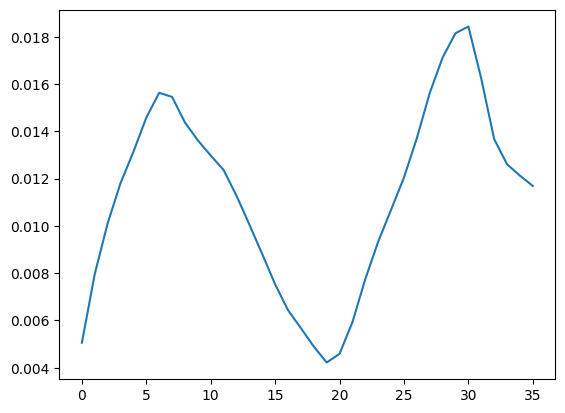

In [35]:
e = past_load_zoom_3_model[2]
plt.plot(e)  
plt.show()

In [36]:
e.mean()

0.011270251772807223

In [37]:
np.linalg.norm(e, ord=np.inf)

0.018438701552373427

<function matplotlib.pyplot.show(close=None, block=None)>

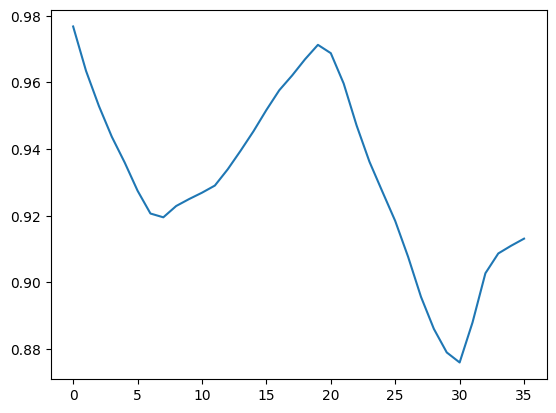

In [38]:
alpha = np.array([e[i]/phi_close_up[i] for i in range(36)])
n = 3
proportion = 1-n*alpha
plt.plot(proportion)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

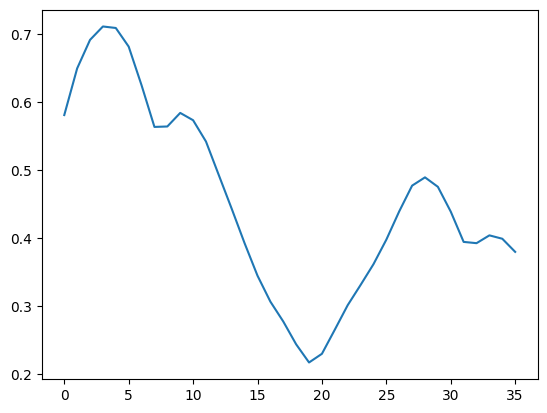

In [39]:
contribution = np.array([phi_close_up[i]/N[i] for i in range(36)])
plt.plot(contribution)
plt.show

In [40]:
m=1
fig = go.Figure()
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(size=11,color='gray'),
    font_family='Helvetica',
    width=1000
)
x = list(range(-180, 1, 1))
for t in range(0,36,m):
    color_index =  int((t-1)/4)
    load_explain = np.concatenate([np.ones(60) * past_load_zoom_1_model[1][0][t]/60, 
                              np.ones(20) * past_load_zoom_2_model[1][0][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][1][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][2][t]/20,     
                              np.ones(20) * past_load_zoom_3_model[1][0][t]/20,
                              np.ones(20) * past_load_zoom_3_model[1][1][t]/20,
                              np.ones(20) * past_load_zoom_3_model[1][2][t]/20]
                                 )
    fig.add_trace(go.Line(x=x, y=load_explain,
                    fill='tozeroy',
                    line=dict(color=rgb_to_rgba(px.colors.qualitative.Prism[color_index],1)),
                    name='h: ' + str(t+1)))
    fig.update_yaxes(showticklabels=False)
    fig.update_xaxes(title_text='past window hours')
    fig.update_traces(showlegend=False)
fig.show()

/Users/juliowaissman/Documents/explaniability-forecasting-with-close-up/venv/lib/python3.9/site-packages/plotly/graph_objs/_deprecations.py:378: DeprecationWarning: plotly.graph_objs.Line is deprecated.
Please replace it with one of the following more specific types
  - plotly.graph_objs.scatter.Line
  - plotly.graph_objs.layout.shape.Line
  - etc.

  warnings.warn(


# Iteration 3

In [41]:
### Zoom over [-40,-20)
component_names = ['[-40,-30)','[-30,-20)']

def past_load_zoom_4(X):
    X_split = {'rest_past_load_before': X[0][:-40,0:1], # fixed rest
               0: X[0][-40:-30,0:1], # [-40,-30)
               1: X[0][-30:-20,0:1], # [-30,-20)
               'rest_past_load_after': X[0][-20:,0:1], # fixed rest
               'rest_calendar':[X[0][:,1:4],X[1][:,0:3]], # fixed rest
               'rest_weather': [X[0][:,4:5],X[1][:,3:4]], # fixed rest
               'rest_holiday': [X[0][:,5:15],X[1][:,4:14]] # fixed rest 
                }         
    return X_split

def join_past_load_zoom_4(X_split):
    X_past_load = np.concatenate([X_split['rest_past_load_before'],X_split[0],X_split[1],X_split['rest_past_load_after']], axis = 0).reshape(180, 1)
    X_encoder = np.concatenate([X_past_load,X_split['rest_calendar'][0], X_split['rest_weather'][0], X_split['rest_holiday'][0]], axis = 1).reshape(180, 15)
    X_decoder = np.concatenate([X_split['rest_calendar'][1],X_split['rest_weather'][1],X_split['rest_holiday'][1]], axis = 1).reshape(36, 14)
    return [X_encoder,X_decoder]

In [42]:
phi_zero = initial_explainability_model[0]
phi_close_up = past_load_zoom_3_model[1][1]
FTP_past_load_zoom_4 = time.elements(model, 
                                     X_train_sample, 
                                     component_to_close_up=phi_close_up, 
                                     initial_bias=phi_zero, 
                                     split_func=past_load_zoom_4, 
                                     joint_func=join_past_load_zoom_4
                                    )

In [43]:
past_load_zoom_4_model = FTP_past_load_zoom_4.close_up_explainability_model(X_observation)
base_vector = -phi_zero
fig = time.local_plot(past_load_zoom_4_model,component_names,base_vector)
fig.show()

4/4 [==============================] - 0s 10ms/step


In [44]:
m=1
fig = go.Figure()
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(size=11,color='gray'),
    font_family='Helvetica',
    width=1000
)
x = list(range(-180, 1, 1))
for t in range(0,36,m):
    color_index =  int((t-1)/4)
    load_explain = np.concatenate([np.ones(60) * past_load_zoom_1_model[1][0][t]/60, 
                              np.ones(20) * past_load_zoom_2_model[1][0][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][1][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][2][t]/20,     
                              np.ones(20) * past_load_zoom_3_model[1][0][t]/20,
                              np.ones(10) * past_load_zoom_4_model[1][0][t]/10,
                              np.ones(10) * past_load_zoom_4_model[1][1][t]/10,
                              np.ones(20) * past_load_zoom_3_model[1][2][t]/20]
                                 )
    fig.add_trace(go.Line(x=x, y=load_explain,
                    fill='tozeroy',
                    line=dict(color=rgb_to_rgba(px.colors.qualitative.Prism[color_index],1)),
                    name='h: ' + str(t+1)))
    fig.update_yaxes(showticklabels=False)
    fig.update_xaxes(title_text='past window hours')
    fig.update_traces(showlegend=False)
fig.show()

/Users/juliowaissman/Documents/explaniability-forecasting-with-close-up/venv/lib/python3.9/site-packages/plotly/graph_objs/_deprecations.py:378: DeprecationWarning: plotly.graph_objs.Line is deprecated.
Please replace it with one of the following more specific types
  - plotly.graph_objs.scatter.Line
  - plotly.graph_objs.layout.shape.Line
  - etc.

  warnings.warn(


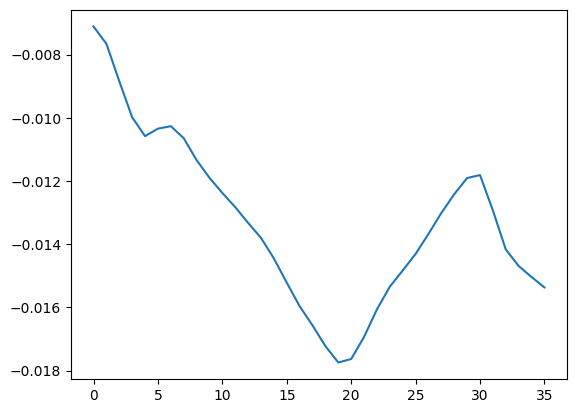

In [45]:
e = past_load_zoom_4_model[2]
plt.plot(e)  
plt.show()

In [46]:
e.mean()

-0.013288279766324206

In [47]:
np.linalg.norm(e, ord=np.inf)

0.017745558034490683

<function matplotlib.pyplot.show(close=None, block=None)>

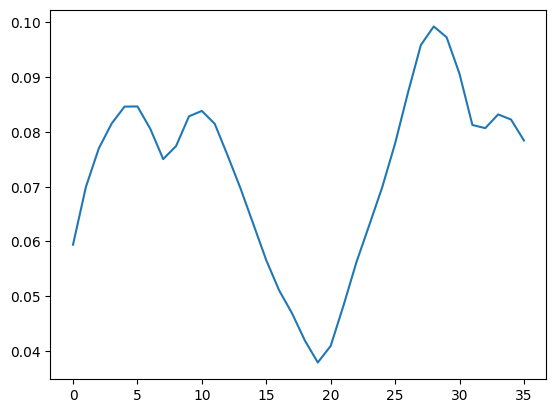

In [48]:
contribution = np.array([phi_close_up[i]/N[i] for i in range(36)])
plt.plot(contribution)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

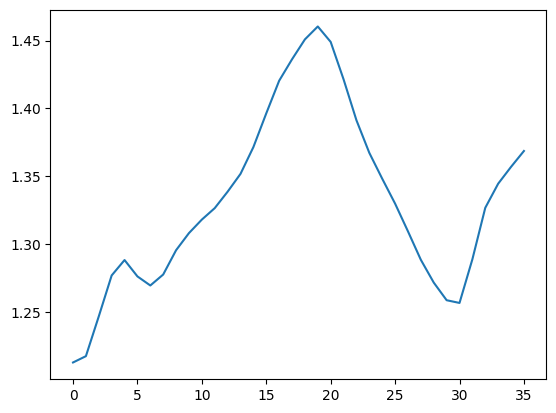

In [49]:
alpha = np.array([e[i]/phi_close_up[i] for i in range(36)])
n = 2
proportion = 1-n*alpha
plt.plot(proportion)
plt.show

In [50]:
### Zoom over [-20,0]
component_names = ['[-20,-10)','[-10,0]']

def past_load_zoom_5(X):
    X_split = {'rest_past_load_before': X[0][:-20,0:1], # fixed rest
               0: X[0][-20:-10,0:1], # '[-20,-10)
               1: X[0][-10:,0:1], # [-10,0]
               'rest_calendar':[X[0][:,1:4],X[1][:,0:3]], # fixed rest
               'rest_weather': [X[0][:,4:5],X[1][:,3:4]], # fixed rest
               'rest_holiday': [X[0][:,5:15],X[1][:,4:14]] # fixed rest 
                }         
    return X_split

def join_past_load_zoom_5(X_split):
    X_past_load = np.concatenate([X_split['rest_past_load_before'],X_split[0],X_split[1]], axis = 0).reshape(180, 1)
    X_encoder = np.concatenate([X_past_load,X_split['rest_calendar'][0], X_split['rest_weather'][0], X_split['rest_holiday'][0]], axis = 1).reshape(180, 15)
    X_decoder = np.concatenate([X_split['rest_calendar'][1],X_split['rest_weather'][1],X_split['rest_holiday'][1]], axis = 1).reshape(36, 14)
    return [X_encoder,X_decoder]

In [51]:
phi_zero = initial_explainability_model[0]
phi_close_up = past_load_zoom_3_model[1][2]
FTP_past_load_zoom_5 = time.elements(model, 
                                     X_train_sample, 
                                     component_to_close_up=phi_close_up, 
                                     initial_bias=phi_zero, 
                                     split_func=past_load_zoom_5, 
                                     joint_func=join_past_load_zoom_5
                                    )

In [52]:
past_load_zoom_5_model = FTP_past_load_zoom_5.close_up_explainability_model(X_observation)
base_vector = -phi_zero
fig = time.local_plot(past_load_zoom_5_model,component_names,base_vector)
fig.show()

4/4 [==============================] - 0s 11ms/step


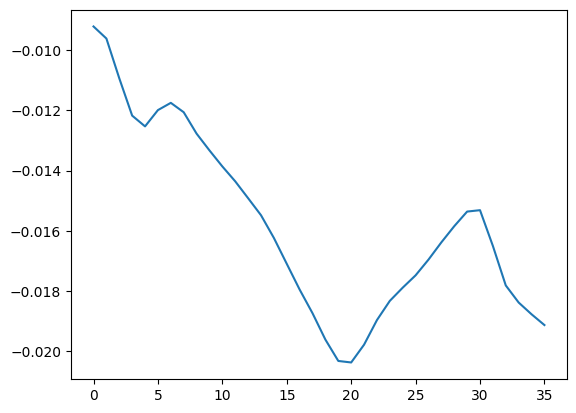

In [53]:
e = past_load_zoom_5_model[2]
plt.plot(e)  
plt.show()

In [54]:
e.mean()

-0.015783223663667495

In [55]:
np.linalg.norm(e, ord=np.inf)

0.020372127769169912

<function matplotlib.pyplot.show(close=None, block=None)>

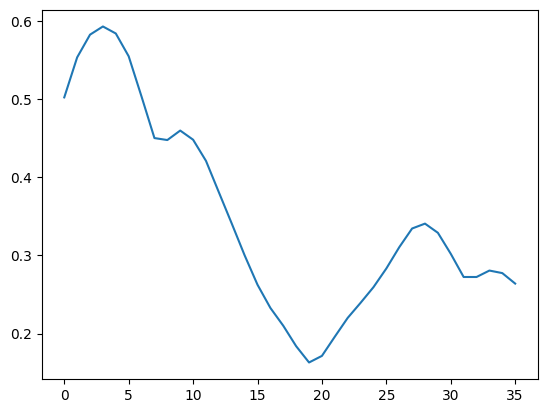

In [56]:
contribution = np.array([phi_close_up[i]/N[i] for i in range(36)])
plt.plot(contribution)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

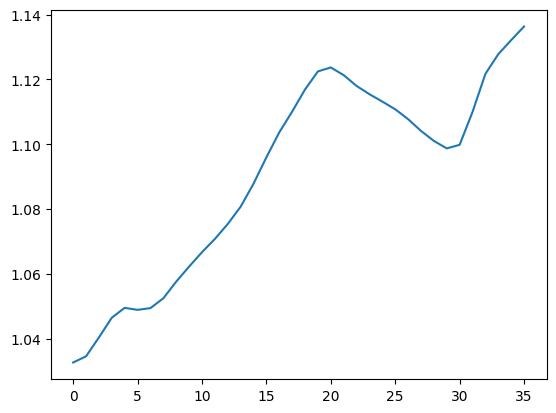

In [57]:
alpha = np.array([e[i]/phi_close_up[i] for i in range(36)])
n = 2
proportion = 1-n*alpha
plt.plot(proportion)
plt.show

In [58]:
m=1
fig = go.Figure()
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(size=11,color='gray'),
    font_family='Helvetica',
    width=1000
)
x = list(range(-180, 1, 1))
for t in range(0,36,m):
    color_index =  int((t-1)/4)
    load_explain = np.concatenate([np.ones(60) * past_load_zoom_1_model[1][0][t]/60, 
                              np.ones(20) * past_load_zoom_2_model[1][0][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][1][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][2][t]/20,     
                              np.ones(20) * past_load_zoom_3_model[1][0][t]/20,
                              np.ones(10) * past_load_zoom_4_model[1][0][t]/10,
                              np.ones(10) * past_load_zoom_4_model[1][1][t]/10,
                              np.ones(10) * past_load_zoom_5_model[1][0][t]/10,
                              np.ones(10) * past_load_zoom_5_model[1][1][t]/10]
                                 )
    fig.add_trace(go.Line(x=x, y=load_explain,
                    fill='tozeroy',
                    line=dict(color=rgb_to_rgba(px.colors.qualitative.Prism[color_index],1)),
                    name='h: ' + str(t+1)))
    fig.update_yaxes(showticklabels=False)
    fig.update_xaxes(title_text='past window hours')
    fig.update_traces(showlegend=False)
fig.show()

/Users/juliowaissman/Documents/explaniability-forecasting-with-close-up/venv/lib/python3.9/site-packages/plotly/graph_objs/_deprecations.py:378: DeprecationWarning: plotly.graph_objs.Line is deprecated.
Please replace it with one of the following more specific types
  - plotly.graph_objs.scatter.Line
  - plotly.graph_objs.layout.shape.Line
  - etc.

  warnings.warn(


In [59]:
m=35
fig = go.Figure()
fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(size=11,color='gray'),
    font_family='Helvetica',
    width=1000
)
x = list(range(-180, 1, 1))
for t in range(0,36,m):
    color_index =  int((t-1)/4)
    load_explain = np.concatenate([np.ones(60) * past_load_zoom_1_model[1][0][t]/60, 
                              np.ones(20) * past_load_zoom_2_model[1][0][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][1][t]/20,
                              np.ones(20) * past_load_zoom_2_model[1][2][t]/20,     
                              np.ones(20) * past_load_zoom_3_model[1][0][t]/20,
                              np.ones(10) * past_load_zoom_4_model[1][0][t]/10,
                              np.ones(10) * past_load_zoom_4_model[1][1][t]/10,
                              np.ones(10) * past_load_zoom_5_model[1][0][t]/10,
                              np.ones(10) * past_load_zoom_5_model[1][1][t]/10]
                                 )
    fig.add_trace(go.Line(x=x, y=load_explain,
                    fill='tozeroy',
                    line=dict(color=rgb_to_rgba(px.colors.qualitative.Prism[color_index],1)),
                    name='h: ' + str(t+1)))
    fig.update_yaxes(showticklabels=False)
    fig.update_xaxes(title_text='past window hours')
    fig.update_traces(showlegend=False)
fig.show()